In [1]:
%pip install ucimlrepo

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

#Descargar el dataset oficial de UCI
concrete = fetch_ucirepo(id=165)

#Separar caracteristicas y variable objetivo
X = concrete.data.features.copy()
y = concrete.data.targets.copy()

#Dataset completo para inspección inicial
df = pd.concat([X,y], axis=1)

In [4]:
print("Dimensiones de x:", X.shape)
print("Dimensiones de y:", y.shape)

display(df.head())
display(df.dtypes)

print("\nValores faltantes:")
display(df.isna().sum())

print("\nInformación del dataset:")
df.info()

Dimensiones de x: (1030, 8)
Dimensiones de y: (1030, 1)


,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Concrete compressive strength
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


Cement                           float64
Blast Furnace Slag               float64
Fly Ash                          float64
Water                            float64
Superplasticizer                 float64
Coarse Aggregate                 float64
Fine Aggregate                   float64
Age                                int64
Concrete compressive strength    float64
dtype: object


Valores faltantes:


Cement                           0
Blast Furnace Slag               0
Fly Ash                          0
Water                            0
Superplasticizer                 0
Coarse Aggregate                 0
Fine Aggregate                   0
Age                              0
Concrete compressive strength    0
dtype: int64


Información del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Cement                         1030 non-null   float64
 1   Blast Furnace Slag             1030 non-null   float64
 2   Fly Ash                        1030 non-null   float64
 3   Water                          1030 non-null   float64
 4   Superplasticizer               1030 non-null   float64
 5   Coarse Aggregate               1030 non-null   float64
 6   Fine Aggregate                 1030 non-null   float64
 7   Age                            1030 non-null   int64  
 8   Concrete compressive strength  1030 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 72.6 KB


In [5]:
display(concrete.variables)

,name,role,type,demographic,description,units,missing_values
0,Cement,Feature,Continuous,None,None,kg/m^3,no
1,Blast Furnace Slag,Feature,Integer,None,None,kg/m^3,no
2,Fly Ash,Feature,Continuous,None,None,kg/m^3,no
3,Water,Feature,Continuous,None,None,kg/m^3,no
4,Superplasticizer,Feature,Continuous,None,None,kg/m^3,no
5,Coarse Aggregate,Feature,Continuous,None,None,kg/m^3,no
6,Fine Aggregate,Feature,Continuous,None,None,kg/m^3,no
7,Age,Feature,Integer,None,None,day,no
8,Concrete compressive strength,Target,Continuous,None,None,MPa,no


In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.20, random_state=42)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test", y_test.shape)

X_train: (824, 8)
X_test: (206, 8)
y_train: (824, 1)
y_test (206, 1)


In [7]:
target_name = y_train.columns[0]
display(y_train)
display(target_name)

,Concrete compressive strength
995,27.68
507,62.05
334,23.80
848,33.40
294,7.40
...,...
87,24.40
330,42.22
466,33.56
121,68.30


'Concrete compressive strength'

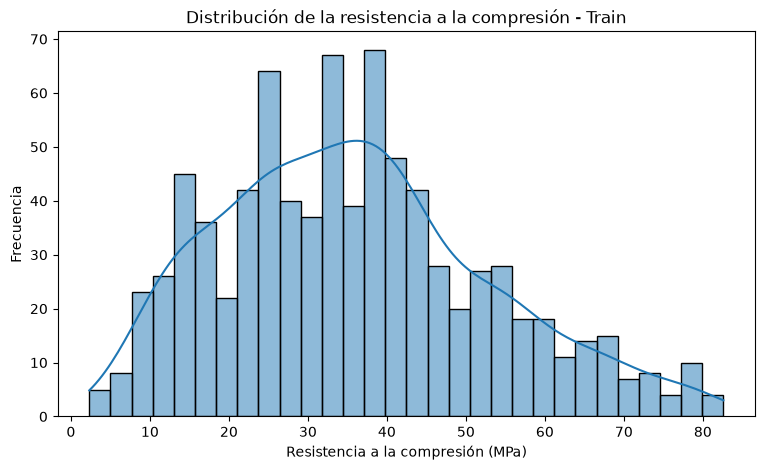

In [8]:
plt.figure(figsize=(9,5))
sns.histplot(
    data=y_train,
    x=target_name,
    bins=30,
    kde=True
)

plt.title("Distribución de la resistencia a la compresión - Train")
plt.xlabel("Resistencia a la compresión (MPa)")
plt.ylabel("Frecuencia")
plt.show()

In [9]:
y_train.mean()

Concrete compressive strength    35.857864
dtype: float64

In [10]:
y_train.max()

Concrete compressive strength    82.6
dtype: float64

In [11]:
#Investigar relación lineal con la resistencia
train_df = pd.concat([X_train,y_train], axis=1)

correlations = (
    train_df
    .corr(numeric_only=True)[target_name]
    .sort_values(ascending=False)
)

display(correlations)

Concrete compressive strength    1.000000
Cement                           0.496686
Superplasticizer                 0.353292
Age                              0.332074
Blast Furnace Slag               0.155159
Fly Ash                         -0.149749
Fine Aggregate                  -0.158425
Coarse Aggregate                -0.171612
Water                           -0.284590
Name: Concrete compressive strength, dtype: float64

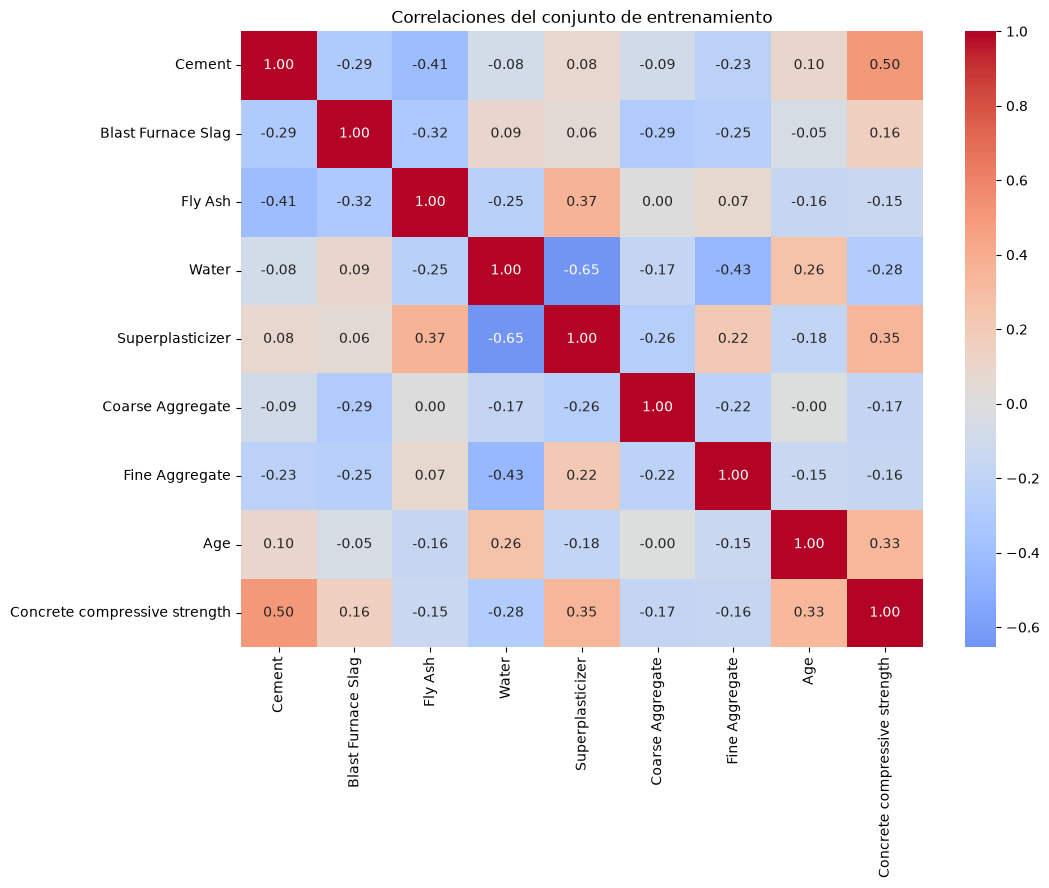

In [12]:
plt.figure(figsize=(11,8))

sns.heatmap(
    train_df.corr(numeric_only=True),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlaciones del conjunto de entrenamiento")
plt.show()

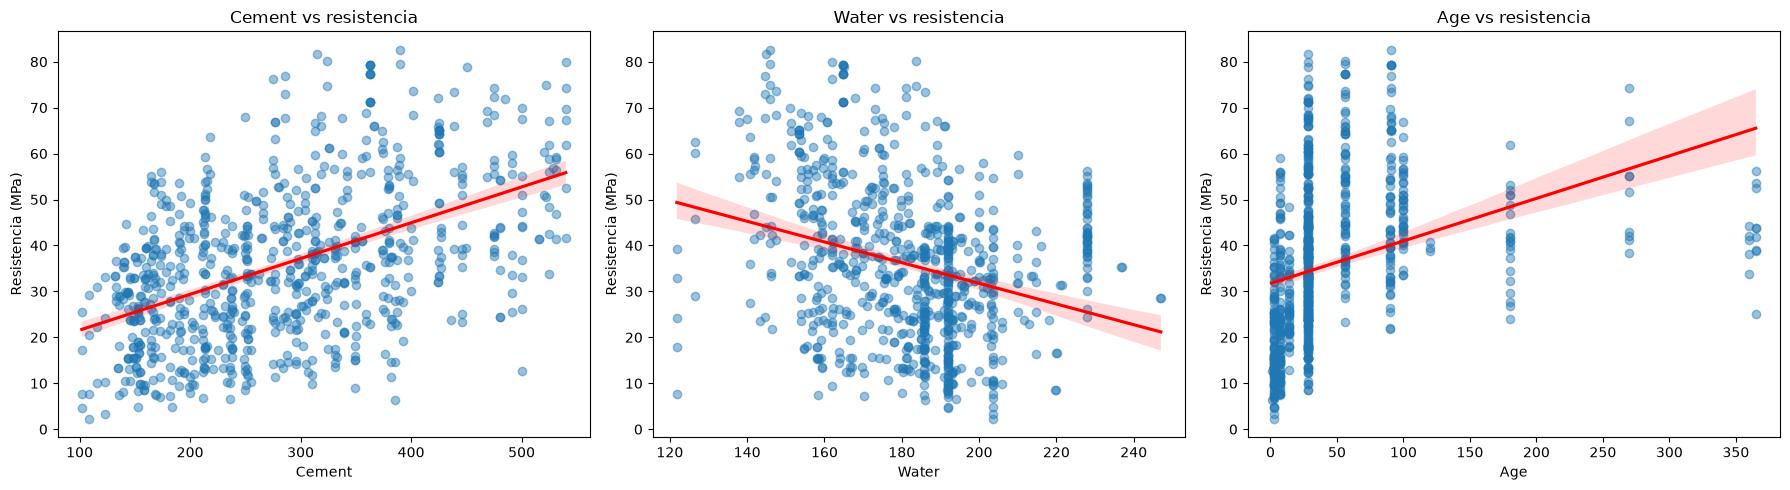

In [13]:
features_to_plot = [
    "Cement",
    "Water",
    "Age"
]

fig, axes = plt.subplots(1,3, figsize=(18,5))

for feature, ax in zip(features_to_plot, axes):
    sns.regplot(
        data=train_df,
        x=feature,
        y=target_name,
        scatter_kws={"alpha":0.45},
        line_kws={"color":"red"},
        ax=ax
    )
    
    ax.set_title(f"{feature} vs resistencia")
    ax.set_ylabel("Resistencia (MPa)")

plt.tight_layout()
plt.show()

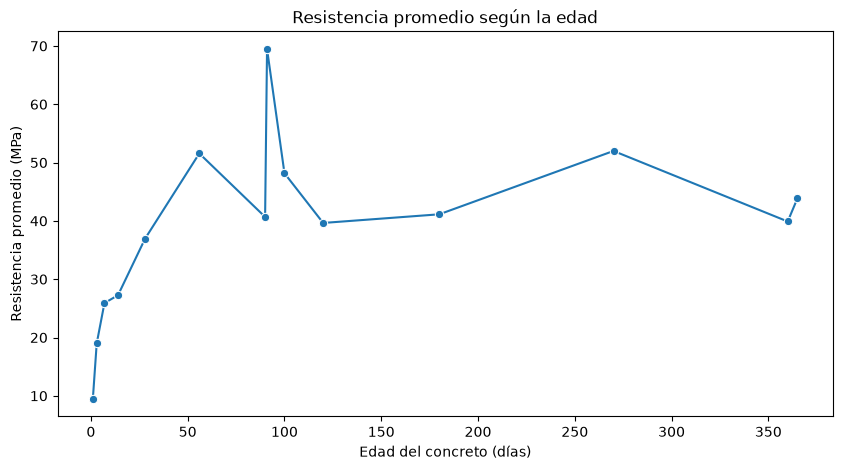

In [14]:
age_strength = (
    train_df.groupby("Age", as_index=False)[target_name]
    .mean()
    .sort_values("Age")
)

plt.figure(figsize=(10,5))

sns.lineplot(
    data=age_strength,
    x="Age",
    y=target_name,
    marker="o"
)

plt.title("Resistencia promedio según la edad")
plt.xlabel("Edad del concreto (días)")
plt.ylabel("Resistencia promedio (MPa)")
plt.show()

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import KFold, cross_validate

y_train_1d = y_train.squeeze()
baseline = DummyRegressor(strategy="mean")

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

baseline_scores = cross_validate(
    baseline,
    X_train,
    y_train_1d,
    cv=cv,
    scoring={
        "mae":"neg_mean_absolute_error",
        "rmse":"neg_root_mean_squared_error",
        "r2":"r2"
    }
)

baseline_mae = -baseline_scores["test_mae"].mean()
baseline_rmse = -baseline_scores["test_rmse"].mean()
baseline_r2 = baseline_scores["test_r2"].mean()

print(f"Baseline MAE promedio:  {baseline_mae:.2f} MPa")
print(f"Baseline RMSE promedio: {baseline_rmse:.2f} MPa")
print(f"Baseline R² promedio:   {baseline_r2:.3f}")

Baseline MAE promedio:  13.58 MPa
Baseline RMSE promedio: 16.89 MPa
Baseline R² promedio:   -0.012


In [16]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_scores = cross_validate(
    linear_model,
    X_train,
    y_train_1d,
    cv=cv,
    scoring={
        "mae":"neg_mean_absolute_error",
        "rmse": "neg_root_mean_squared_error",
        "r2":"r2"
    },
    return_train_score=True
)

In [17]:
linear_results = {
    "MAE Train": -linear_scores["train_mae"].mean(),
    "MAE Validation": -linear_scores["test_mae"].mean(),
    "RMSE Train": -linear_scores["train_rmse"].mean(),
    "RMSE Validation": -linear_scores["test_rmse"].mean(),
    "R² Train": linear_scores["train_r2"].mean(),
    "R² Validation": linear_scores["test_r2"].mean()
}

for metric, value in linear_results.items():
    print(f"{metric}: {value:.3f}")

MAE Train: 8.311
MAE Validation: 8.422
RMSE Train: 10.505
RMSE Validation: 10.627
R² Train: 0.611
R² Validation: 0.597


In [18]:
linear_model.fit(X_train, y_train_1d)
print(f"Intercepto: {linear_model.intercept_:.3f} MPa")

Intercepto: -28.824 MPa


In [19]:
coefficients = pd.DataFrame({
    "Característica": X_train.columns,
    "Coeficiente": linear_model.coef_
})

coefficients = coefficients.sort_values(
    by="Coeficiente",
    ascending=False
)

display(coefficients)

,Característica,Coeficiente
4,Superplasticizer,0.310570
0,Cement,0.118994
7,Age,0.116439
1,Blast Furnace Slag,0.108536
2,Fly Ash,0.082152
6,Fine Aggregate,0.024100
5,Coarse Aggregate,0.017867
3,Water,-0.135276


In [20]:
from sklearn.model_selection import cross_val_predict

oof_predictions = cross_val_predict(
    linear_model,
    X_train,
    y_train_1d,
    cv=cv
)

residuals = y_train_1d.to_numpy() - oof_predictions

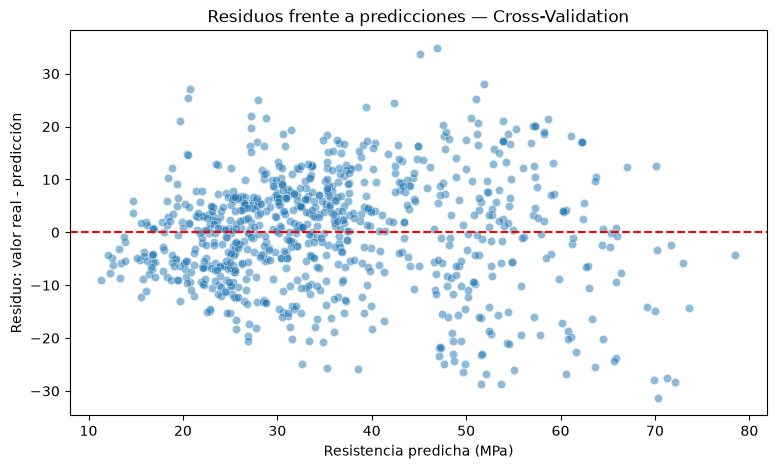

In [21]:
plt.figure(figsize=(9,5))

sns.scatterplot(
    x=oof_predictions,
    y=residuals,
    alpha=0.5
)

plt.axhline(
    y=0, 
    color="red",
    linestyle="--"
)

plt.title("Residuos frente a predicciones — Cross-Validation")
plt.xlabel("Resistencia predicha (MPa)")
plt.ylabel("Residuo: valor real - predicción")
plt.show()

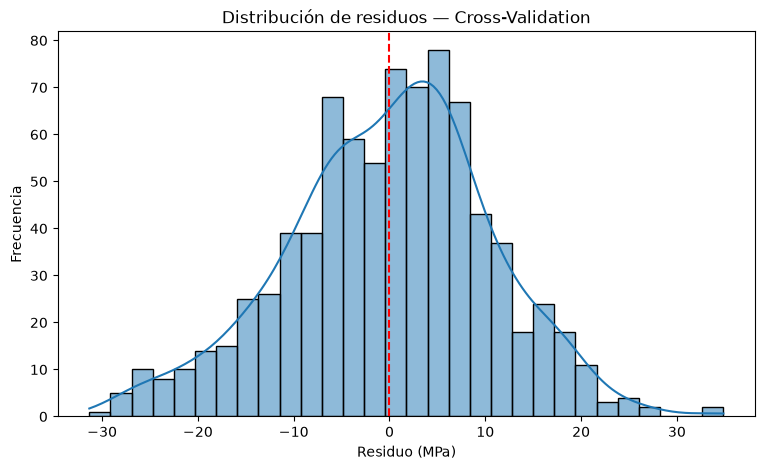

In [22]:
plt.figure(figsize=(9,5))

sns.histplot(
    residuals,
    bins=30,
    kde=True
)

plt.axvline(
    x=0, 
    color="red",
    linestyle="--"
)

plt.title("Distribución de residuos — Cross-Validation")
plt.xlabel("Residuo (MPa)")
plt.ylabel("Frecuencia")
plt.show()

In [23]:
residual_summary = pd.Series(residuals).describe()
display(residual_summary)

print(f"Media de residuos: {residuals.mean():.3f} MPa")
print(f"Mediana de residuos: {np.median(residuals):.3f} MPa")

count    824.000000
mean      -0.049724
std       10.644857
min      -31.331761
25%       -6.485014
50%        0.724732
75%        6.678993
max       34.853855
dtype: float64

Media de residuos: -0.050 MPa
Mediana de residuos: 0.725 MPa


In [24]:
residual_analysis = X_train.copy()

residual_analysis["Valor real"] = y_train_1d
residual_analysis["Predicción"] = oof_predictions
residual_analysis["Residuo"] = residuals
residual_analysis["Error absoluto"] = np.abs(residuals)

largest_errors = (
    residual_analysis
    .sort_values("Error absoluto", ascending=False)
    .head(10)
)

display(largest_errors)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Valor real,Predicción,Residuo,Error absoluto
381,315.0,137.0,0.0,145.0,5.9,1130.0,745.0,28,81.75,46.896145,34.853855,34.853855
383,451.0,0.0,0.0,165.0,11.3,1030.0,745.0,28,78.80,45.114699,33.685301,33.685301
42,237.5,237.5,0.0,228.0,0.0,932.0,594.0,365,39.00,70.331761,-31.331761,31.331761
114,362.6,189.0,0.0,164.9,11.6,944.7,755.8,7,22.90,51.565297,-28.665297,28.665297
610,236.0,0.0,0.0,193.0,0.0,968.0,885.0,365,25.08,53.684206,-28.604206,28.604206
41,427.5,47.5,0.0,228.0,0.0,932.0,594.0,365,43.70,72.097252,-28.397252,28.397252
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99,51.917535,28.072465,28.072465
56,475.0,0.0,0.0,228.0,0.0,932.0,594.0,365,41.93,69.847652,-27.917652,27.917652
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,365,43.70,71.224881,-27.524881,27.524881
14,304.0,76.0,0.0,228.0,0.0,932.0,670.0,28,47.81,20.802494,27.007506,27.007506


In [25]:
X_train_log = X_train.copy()

X_train_log["Age"] = np.log1p(X_train_log["Age"])

In [26]:
linear_log_model = LinearRegression()

linear_log_scores = cross_validate(
    linear_log_model,
    X_train_log,
    y_train_1d,
    cv=cv,
    scoring={
        "mae":"neg_mean_absolute_error",
        "rmse":"neg_root_mean_squared_error",
        "r2":"r2"
    },
    return_train_score=True
)

linear_log_results = {
    "MAE Train": -linear_log_scores["train_mae"].mean(),
    "MAE Validation": -linear_log_scores["test_mae"].mean(),
    "RMSE Train": -linear_log_scores["train_rmse"].mean(),
    "RMSE Validation": -linear_log_scores["test_rmse"].mean(),
    "R² Train": linear_log_scores["train_r2"].mean(),
    "R² Validation": linear_log_scores["test_r2"].mean()
}

for metric, value in linear_log_results.items():
    print(f"{metric}: {value:.3f}")



MAE Train: 5.557
MAE Validation: 5.612
RMSE Train: 7.291
RMSE Validation: 7.352
R² Train: 0.813
R² Validation: 0.807


In [27]:
X_test_log = X_test.copy()
X_test_log["Age"] = np.log1p(X_test_log["Age"])

In [28]:
final_model = LinearRegression()
final_model.fit(
    X_train_log,
    y_train_1d
)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[0.13,0.12,0.09,...,0.03,0.04,9.4 ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](8,)","['Cement','Blast Furnace Slag','Fly Ash',...,'Coarse Aggregate', 'Fine Aggregate','Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-77.18
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(8)


In [29]:
y_test_1d = y_test.squeeze()
test_predictions = final_model.predict(X_test_log)

In [30]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

test_mae = mean_absolute_error(y_test_1d,test_predictions)

test_mse = mean_squared_error(y_test_1d, test_predictions)

test_rmse = np.sqrt(test_mse)

test_r2 = r2_score(y_test_1d, test_predictions)

print(f"MAE Test:  {test_mae:.3f} MPa")
print(f"MSE Test:  {test_mse:.3f} MPa²")
print(f"RMSE Test: {test_rmse:.3f} MPa")
print(f"R² Test:   {test_r2:.3f}")

MAE Test:  5.320 MPa
MSE Test:  44.576 MPa²
RMSE Test: 6.676 MPa
R² Test:   0.827


In [31]:
cv_summary = {
    "MAE media": -linear_log_scores["test_mae"].mean(),
    "MAE desviación": linear_log_scores["test_mae"].std(),

    "RMSE media": -linear_log_scores["test_rmse"].mean(),
    "RMSE desviación": linear_log_scores["test_rmse"].std(),

    "R² media": linear_log_scores["test_r2"].mean(),
    "R² desviación": linear_log_scores["test_r2"].std()
}

for metric, value in cv_summary.items():
    print(f"{metric}: {value:.3f}")

MAE media: 5.612
MAE desviación: 0.351
RMSE media: 7.352
RMSE desviación: 0.425
R² media: 0.807
R² desviación: 0.023


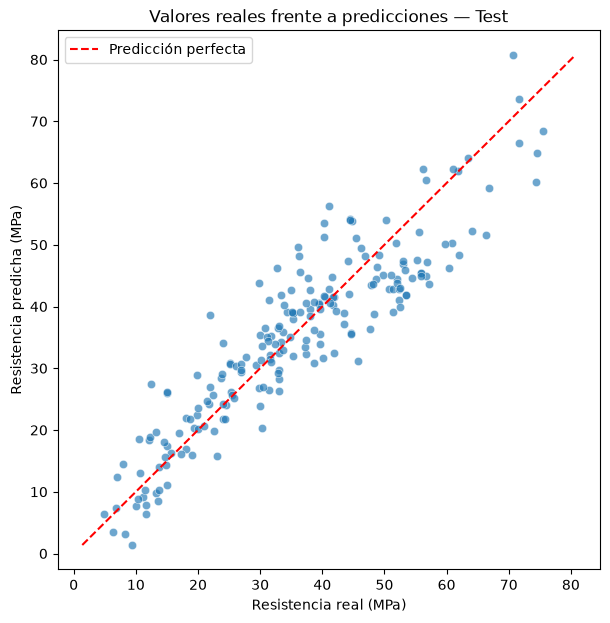

In [32]:
plt.figure(figsize=(7, 7))

sns.scatterplot(
    x=y_test_1d,
    y=test_predictions,
    alpha=0.65
)

minimum = min(y_test_1d.min(), test_predictions.min())
maximum = max(y_test_1d.max(), test_predictions.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="red",
    linestyle="--",
    label="Predicción perfecta"
)

plt.title("Valores reales frente a predicciones — Test")
plt.xlabel("Resistencia real (MPa)")
plt.ylabel("Resistencia predicha (MPa)")
plt.legend()
plt.show()

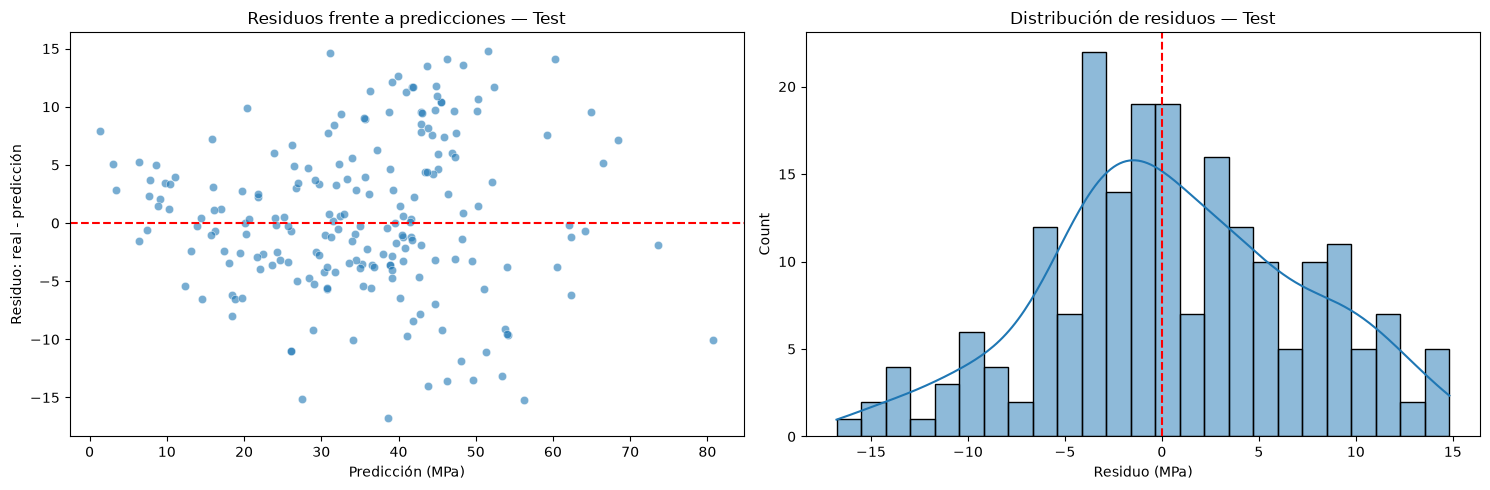

In [33]:
test_residuals = y_test_1d.to_numpy() - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.scatterplot(
    x=test_predictions,
    y=test_residuals,
    alpha=0.6,
    ax=axes[0]
)

axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_title("Residuos frente a predicciones — Test")
axes[0].set_xlabel("Predicción (MPa)")
axes[0].set_ylabel("Residuo: real - predicción")

sns.histplot(
    test_residuals,
    bins=25,
    kde=True,
    ax=axes[1]
)

axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Distribución de residuos — Test")
axes[1].set_xlabel("Residuo (MPa)")

plt.tight_layout()
plt.show()

In [34]:
test_analysis = X_test.copy()

test_analysis["Valor real"] = y_test_1d
test_analysis["Predicción"] = test_predictions
test_analysis["Residuo"] = test_residuals
test_analysis["Error absoluto"] = np.abs(test_residuals)

display(
    test_analysis
    .sort_values("Error absoluto", ascending=False)
    .head(10)
)

,Cement,Blast Furnace Slag,Fly Ash,Water,Superplasticizer,Coarse Aggregate,Fine Aggregate,Age,Valor real,Predicción,Residuo,Error absoluto
584,228.0,342.1,0.0,185.7,0.0,955.8,674.3,7,21.92,38.694671,-16.774671,16.774671
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05,56.273710,-15.223710,15.223710
581,181.9,272.8,0.0,185.7,0.0,1012.4,714.3,7,12.37,27.523247,-15.153247,15.153247
333,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,100,66.42,51.598600,14.821400,14.821400
231,213.7,98.1,24.5,181.7,6.9,1065.8,785.4,28,45.71,31.126544,14.583456,14.583456
514,424.0,22.0,132.0,168.0,8.9,822.0,750.0,56,74.36,60.216381,14.143619,14.143619
332,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,56,60.32,46.222535,14.097465,14.097465
620,254.0,0.0,0.0,198.0,0.0,968.0,863.0,365,29.79,43.821480,-14.031480,14.031480
362,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,56,61.99,48.381694,13.608306,13.608306
762,350.0,0.0,0.0,203.0,0.0,974.0,775.0,180,32.72,46.261101,-13.541101,13.541101


In [35]:
largest_test_error = test_analysis.loc[
    test_analysis["Error absoluto"].idxmax()
]

display(largest_test_error)

Cement                228.000000
Blast Furnace Slag    342.100000
Fly Ash                 0.000000
Water                 185.700000
Superplasticizer        0.000000
Coarse Aggregate      955.800000
Fine Aggregate        674.300000
Age                     7.000000
Valor real             21.920000
Predicción             38.694671
Residuo               -16.774671
Error absoluto         16.774671
Name: 584, dtype: float64

In [ ]:
print(
    f"Mayor error absoluto: "
    f"{test_analysis['Error absoluto'].max():.3f} MPa"
)

Mayor error absoluto: 16.775 MPa


In [37]:
model_comparison = pd.DataFrame({
    "Modelo": [
        "Baseline",
        "Regresión lineal",
        "Regresión lineal + log(Age)"
    ],
    "MAE Validation": [
        13.580,
        8.422,
        5.612
    ],
    "RMSE Validation": [
        16.890,
        10.627,
        7.352
    ],
    "R² Validation": [
        -0.012,
        0.597,
        0.807
    ]
})

display(model_comparison)

,Modelo,MAE Validation,RMSE Validation,R² Validation
0,Baseline,13.580,16.890,-0.012
1,Regresión lineal,8.422,10.627,0.597
2,Regresión lineal + log(Age),5.612,7.352,0.807


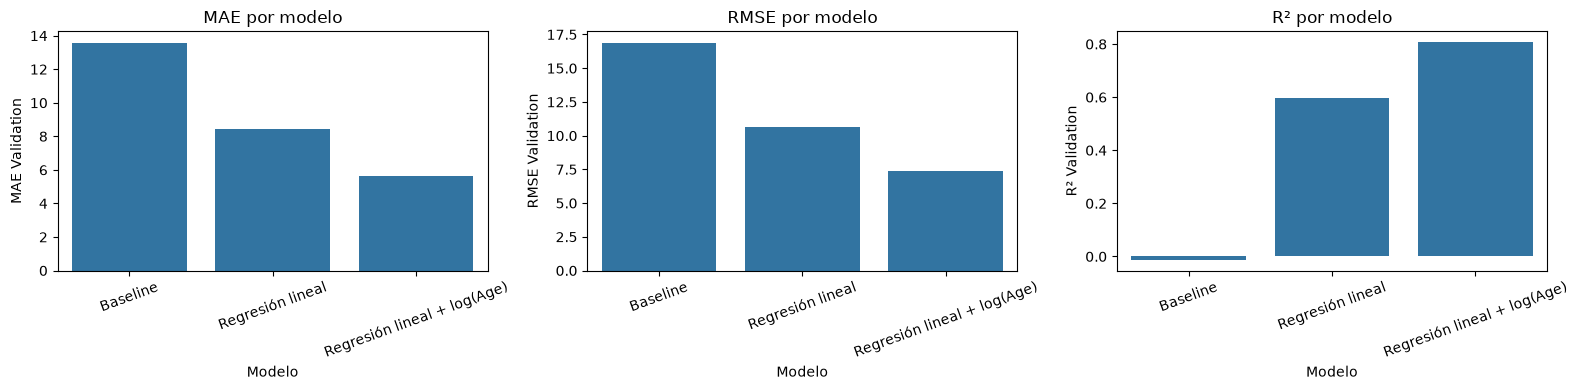

In [38]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(
    data=model_comparison,
    x="Modelo",
    y="MAE Validation",
    ax=axes[0]
)
axes[0].set_title("MAE por modelo")
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    data=model_comparison,
    x="Modelo",
    y="RMSE Validation",
    ax=axes[1]
)
axes[1].set_title("RMSE por modelo")
axes[1].tick_params(axis="x", rotation=20)

sns.barplot(
    data=model_comparison,
    x="Modelo",
    y="R² Validation",
    ax=axes[2]
)
axes[2].set_title("R² por modelo")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

## Conclusiones

En este proyecto se construyó un modelo de regresión lineal múltiple para
predecir la resistencia a la compresión del concreto a partir de ocho
características relacionadas con su composición y edad.

Como referencia inicial se utilizó un DummyRegressor que siempre predecía
la media de resistencia. Este baseline obtuvo aproximadamente un MAE de
13.58 MPa, un RMSE de 16.89 MPa y un R² cercano a cero en validación
cruzada.

La primera regresión lineal superó claramente al baseline, con un MAE de
8.42 MPa, un RMSE de 10.63 MPa y un R² de 0.597 en validación. Sin embargo,
el análisis exploratorio mostró que la relación entre la edad y la
resistencia no era completamente lineal: la resistencia aumentaba
rápidamente durante los primeros días y posteriormente crecía con menor
rapidez.

Para representar mejor este comportamiento se transformó la edad mediante
log(1 + Age). Esta transformación redujo el MAE de validación a 5.61 MPa,
redujo el RMSE a 7.35 MPa y aumentó el R² a 0.807. La pequeña diferencia
entre Train y Validation no mostró señales importantes de overfitting.

El modelo final se evaluó una sola vez sobre el conjunto Test aislado y
obtuvo:

- MAE: 5.320 MPa
- MSE: 44.576 MPa²
- RMSE: 6.676 MPa
- R²: 0.827

Los resultados de Test fueron consistentes con Cross-Validation. El modelo
explicó aproximadamente el 82.7 % de la variabilidad observada en la
resistencia del conjunto Test.

El análisis visual mostró que la mayoría de las predicciones se encontraba
cerca de los valores reales. No obstante, el modelo presentó una tendencia
a subestimar algunas resistencias altas. El mayor error absoluto en Test
fue de 16.775 MPa: el modelo predijo 38.695 MPa para una mezcla cuya
resistencia real era de 21.92 MPa.

## Limitaciones

- El dataset contiene solamente 1,030 observaciones.
- La regresión lineal representa las relaciones como efectos aditivos y
  puede omitir interacciones complejas entre los ingredientes.
- Algunas características están correlacionadas entre sí, lo que puede
  dificultar la interpretación individual de sus coeficientes.
- Los coeficientes muestran asociaciones, no relaciones causales.
- El modelo puede producir resultados poco confiables al recibir mezclas
  fuera de los rangos observados durante el entrenamiento.
- Aunque la transformación logarítmica de la edad mejoró notablemente el
  rendimiento, todavía existen errores individuales relevantes.
- El modelo debe utilizarse como herramienta de estimación y no como
  sustituto de pruebas físicas de resistencia, especialmente en decisiones
  relacionadas con seguridad estructural.